# **Alzheimer's MRI Classification using Attention-Gated CNN**

# **Loading the Dataset**

In [1]:
!pip install timm grad-cam kaggle -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 34.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# ── CELL 2: Download Dataset from Kaggle ──────────────────────────────────
# Re-running this cell is fine — it skips the download if already extracted.
# =========================================================================

import os

EXTRACT_PATH = '/content/data/oasis/'

if os.path.exists(EXTRACT_PATH) and any(os.scandir(EXTRACT_PATH)):
    print("Dataset already extracted at /content/data/oasis/ — ready to go!")
else:
    print("Setting up Kaggle credentials...")
    from google.colab import files
    print("Upload your kaggle.json when prompted:")
    uploaded = files.upload()  # prompts you to upload kaggle.json

    os.makedirs('/root/.kaggle', exist_ok=True)
    !cp kaggle.json /root/.kaggle/kaggle.json
    !chmod 600 /root/.kaggle/kaggle.json

    print("\nDownloading dataset from Kaggle (~1-2 mins)...")
    os.makedirs('/content/data', exist_ok=True)
    !kaggle datasets download -d ninadaithal/imagesoasis -p /content/data/ --quiet

    print("Unzipping...")
    !unzip -q /content/data/imagesoasis.zip -d {EXTRACT_PATH}
    !rm /content/data/imagesoasis.zip   # free up disk space

    print("Done! Dataset ready at /content/data/oasis/")

# Quick sanity check
print("\nTop-level contents:")
for item in sorted(os.listdir(EXTRACT_PATH)):
    print(f"  {item}/")

Setting up Kaggle credentials...
Upload your kaggle.json when prompted:


Saving kaggle.json to kaggle.json

Dataset URL: https://www.kaggle.com/datasets/ninadaithal/imagesoasis
License(s): apache-2.0
Unzipping...
Done! Dataset ready at /content/data/oasis/

Top-level contents:
  Data/


In [3]:
#Imports


In [33]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, accuracy_score)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: Tesla T4


# **EDA**

In [34]:
# Dataset Exploration

In [35]:
DATA_DIR = '/content/data/oasis/'

# Find the actual folder structure
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, '').count(os.sep)
    indent = ' ' * 2 * level
    if level < 3:
        n_files = len([f for f in files if f.endswith(('.jpg','.jpeg','.png'))])
        print(f'{indent}{os.path.basename(root)}/ ({n_files} images)')

/ (0 images)
Data/ (0 images)
  Moderate Dementia/ (488 images)
  Mild Dementia/ (5002 images)
  Very mild Dementia/ (13725 images)
  Non Demented/ (67222 images)


In [36]:
#Visualize class distribution

In [37]:
# Run this diagnostic cell BEFORE Cell 5
import os

DATA_DIR = '/content/data/oasis/'

print("Full directory tree (first 4 levels):")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, '').count(os.sep)
    if level > 4:
        continue
    indent = '  ' * level
    n_imgs = len([f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))])
    print(f"{indent}{os.path.basename(root)}/ {'(' + str(n_imgs) + ' images)' if n_imgs else ''}")

Full directory tree (first 4 levels):
/ 
Data/ 
  Moderate Dementia/ (488 images)
  Mild Dementia/ (5002 images)
  Very mild Dementia/ (13725 images)
  Non Demented/ (67222 images)


Class distribution:
  Mild Dementia               5002 (5.8%) ██
  Moderate Dementia            488 (0.6%) 
  Non Demented               67222 (77.8%) ██████████████████████████████████████
  Very mild Dementia         13725 (15.9%) ███████


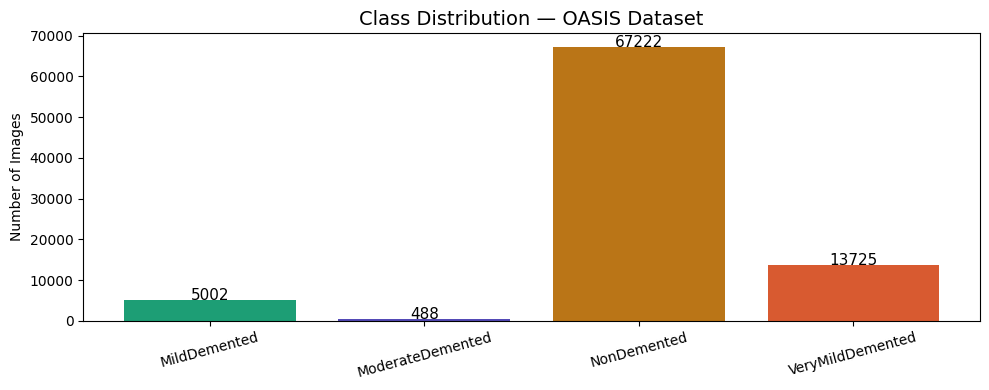

Note: Moderate Dementia is severely underrepresented — must handle imbalance!


In [38]:
train_dir = '/content/data/oasis/Data'

CLASS_NAMES_FOLDER = ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
CLASS_NAMES = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

class_counts = {}
for cls in CLASS_NAMES_FOLDER:
    cls_path = os.path.join(train_dir, cls)
    n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
    class_counts[cls] = n

print("Class distribution:")
total = sum(class_counts.values())
for cls, n in class_counts.items():
    bar = '█' * int(n / total * 50)
    print(f"  {cls:<25} {n:>6} ({n/total*100:.1f}%) {bar}")

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#1D9E75', '#534AB7', '#BA7517', '#D85A30']
bars = ax.bar(CLASS_NAMES, class_counts.values(), color=colors)
ax.set_title("Class Distribution — OASIS Dataset", fontsize=14)
ax.set_ylabel("Number of Images")
for bar, n in zip(bars, class_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            str(n), ha='center', fontsize=11)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print("Note: Moderate Dementia is severely underrepresented — must handle imbalance!")

In [39]:
#Visualize sample images

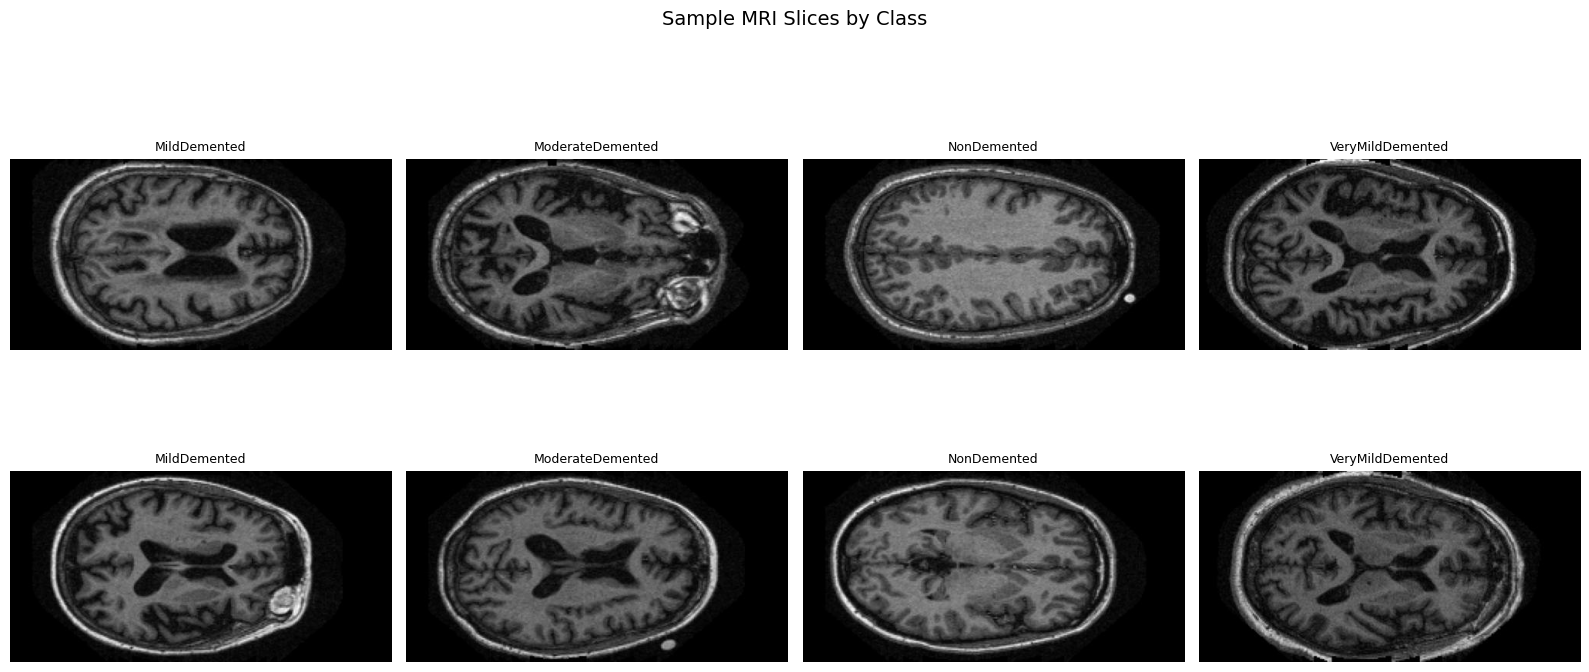

In [40]:
train_dir = '/content/data/oasis/Data'  # add this line

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, cls in enumerate(CLASS_NAMES_FOLDER):
    cls_path = os.path.join(train_dir, cls)
    imgs = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for row in range(2):
        img = Image.open(os.path.join(cls_path, imgs[row])).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(CLASS_NAMES[col], fontsize=9)
        axes[row][col].axis('off')

plt.suptitle("Sample MRI Slices by Class", fontsize=14)
plt.tight_layout()
plt.show()

In [41]:
#Transforms

In [42]:
TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

VAL_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ImageFolder sorts alphabetically — folder names with spaces sort like this:
# 'Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia'
CLASS_NAMES_FOLDER = ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
CLASS_NAMES        = ['MildDemented',  'ModerateDemented',  'NonDemented',  'VeryMildDemented']
N_CLASSES = 4
print(f"Class order (ImageFolder alphabetical): {CLASS_NAMES_FOLDER}")

Class order (ImageFolder alphabetical): ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']


In [43]:
# Dataset Split

In [45]:
SPLIT_PATH = '/content/split_indices.json'

# ── CELL 8: Subject-Level Dataset Split (fixes data leakage) ─────────────────
import os
from collections import defaultdict

full_dataset = datasets.ImageFolder(train_dir, transform=VAL_TRANSFORM)
print("ImageFolder class-to-index mapping:", full_dataset.class_to_idx)

all_indices = list(range(len(full_dataset)))
all_labels  = [full_dataset.targets[i] for i in all_indices]

# Extract subject ID from filename (OAS1_0001_MR1... → OAS1_0001)
subject_to_indices = defaultdict(list)
for idx, (path, label) in enumerate(full_dataset.samples):
    filename = os.path.basename(path)
    parts = filename.split('_')
    subject_id = '_'.join(parts[:2]) if len(parts) >= 2 else filename
    subject_to_indices[subject_id].append((idx, label))

print(f"Total unique subjects: {len(subject_to_indices)}")
print(f"Total images: {len(full_dataset)}")
print(f"Avg slices per subject: {len(full_dataset)/len(subject_to_indices):.1f}")
print("Sample subject IDs:", list(subject_to_indices.keys())[:6])

# Assign each subject its majority class label
subjects = list(subject_to_indices.keys())
subject_labels = []
for s in subjects:
    labels = [l for _, l in subject_to_indices[s]]
    subject_labels.append(max(set(labels), key=labels.count))

from collections import Counter
print("\nSubject-level class distribution:")
for cls_idx, count in sorted(Counter(subject_labels).items()):
    print(f"  {CLASS_NAMES[cls_idx]:<25} {count} subjects")

# ── Split at subject level ────────────────────────────────────────────────────
# Stratify on the FIRST split only (enough subjects per class).
# Second split drops stratify because Moderate Dementia has too few subjects
# to guarantee ≥2 per class after the first split.

SPLIT_PATH = '/content/split_indices_subject_level.json'

if os.path.exists(SPLIT_PATH):
    print("\nLoading existing subject-level split...")
    with open(SPLIT_PATH) as f:
        split = json.load(f)
    train_idx = split['train']
    val_idx   = split['val']
    test_idx  = split['test']

else:
    print("\nGenerating subject-level split...")

    # First split: 70% train, 30% temp — stratified (enough subjects here)
    train_subjects, temp_subjects = train_test_split(
        subjects, test_size=0.3, random_state=42, stratify=subject_labels
    )

    # Second split: 50/50 val/test from temp — NO stratify (too few Moderate subjects)
    val_subjects, test_subjects = train_test_split(
        temp_subjects, test_size=0.5, random_state=42
        # stratify dropped intentionally — Moderate Dementia has <2 subjects in temp
    )

    # Convert subject lists → image index lists
    train_idx = [idx for s in train_subjects for idx, _ in subject_to_indices[s]]
    val_idx   = [idx for s in val_subjects   for idx, _ in subject_to_indices[s]]
    test_idx  = [idx for s in test_subjects  for idx, _ in subject_to_indices[s]]

    split = {'train': train_idx, 'val': val_idx, 'test': test_idx}
    with open(SPLIT_PATH, 'w') as f:
        json.dump(split, f)
    print(f"Saved to {SPLIT_PATH} — share this with teammates!")

    print(f"\nSubject counts: Train {len(train_subjects)} | Val {len(val_subjects)} | Test {len(test_subjects)}")

    # Show class distribution per split so you can verify Moderate made it in
    for name, subs in [("Train", train_subjects), ("Val", val_subjects), ("Test", test_subjects)]:
        cls_counts = Counter(subject_labels[subjects.index(s)] for s in subs)
        print(f"  {name}: " + " | ".join(f"{CLASS_NAMES[c]}: {cls_counts.get(c,0)}" for c in range(N_CLASSES)))

print(f"\nImage counts:")
print(f"  Train: {len(train_idx)} ({len(train_idx)/len(all_indices)*100:.0f}%)")
print(f"  Val:   {len(val_idx)}   ({len(val_idx)/len(all_indices)*100:.0f}%)")
print(f"  Test:  {len(test_idx)}  ({len(test_idx)/len(all_indices)*100:.0f}%)")

# Leakage check — must be 0
overlap = set(train_idx) & set(test_idx)
print(f"\nLeakage check — images in both train AND test: {len(overlap)} (must be 0)")

ImageFolder class-to-index mapping: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
Total unique subjects: 347
Total images: 86437
Avg slices per subject: 249.1
Sample subject IDs: ['OAS1_0028', 'OAS1_0031', 'OAS1_0035', 'OAS1_0052', 'OAS1_0053', 'OAS1_0056']

Subject-level class distribution:
  MildDemented              21 subjects
  ModerateDemented          2 subjects
  NonDemented               266 subjects
  VeryMildDemented          58 subjects

Generating subject-level split...
Saved to /content/split_indices_subject_level.json — share this with teammates!

Subject counts: Train 242 | Val 52 | Test 53
  Train: MildDemented: 15 | ModerateDemented: 1 | NonDemented: 186 | VeryMildDemented: 40
  Val: MildDemented: 4 | ModerateDemented: 0 | NonDemented: 39 | VeryMildDemented: 9
  Test: MildDemented: 2 | ModerateDemented: 1 | NonDemented: 41 | VeryMildDemented: 9

Image counts:
  Train: 59536 (69%)
  Val:   12749   (15%)
  Test:  14152  (16%)



In [46]:
# Data Loaders

In [54]:
BATCH_SIZE = 32

train_dataset = Subset(datasets.ImageFolder(train_dir, transform=TRAIN_TRANSFORM), train_idx)
val_dataset   = Subset(datasets.ImageFolder(train_dir, transform=VAL_TRANSFORM),   val_idx)
test_dataset  = Subset(datasets.ImageFolder(train_dir, transform=VAL_TRANSFORM),   test_idx)

train_labels = [all_labels[i] for i in train_idx]
label_counts = Counter(train_labels)
print("Training class counts (by index):", dict(label_counts))

class_weights = {cls: 1.0/count for cls, count in label_counts.items()}
sample_weights = [class_weights[label] for label in train_labels]

sampler = WeightedRandomSampler(
    weights=torch.FloatTensor(sample_weights),
    num_samples=len(train_dataset),
    replacement=True
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          sampler=sampler, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False,  num_workers=2, pin_memory=True)

total_train = sum(label_counts.values())
loss_weights = torch.tensor(
    [total_train / (N_CLASSES * label_counts[i]) for i in range(N_CLASSES)],
    dtype=torch.float
).to(device)

print(f"\nLoss weights per class:")
for i, (name, w) in enumerate(zip(CLASS_NAMES, loss_weights)):
    print(f"  {name:<20} {w:.3f}x")
print(f"\nTrain batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Training class counts (by index): {2: 46177, 3: 9516, 0: 3599, 1: 244}

Loss weights per class:
  MildDemented         4.136x
  ModerateDemented     61.000x
  NonDemented          0.322x
  VeryMildDemented     1.564x

Train batches: 1861 | Val: 399 | Test: 443


In [18]:
#Model — AttentionGate + AttentionGatedCNN

In [48]:
%%writefile /content/model.py

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


class AttentionGate(nn.Module):
    """
    Attention gate module.
    g: gating signal from deep layer (has semantic context about what to look for)
    x: feature map from shallow layer (has spatial detail we want to selectively keep)
    Returns: filtered feature map + attention map (for visualization)
    """
    def __init__(self, F_g, F_x, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_x, F_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(g1, size=x1.shape[2:],
                               mode='bilinear', align_corners=True)
        attn = self.psi(self.relu(g1 + x1))
        return x * attn, attn


class AttentionGatedCNN(nn.Module):
    """
    Attention-Gated CNN for Alzheimer's MRI classification.

    Architecture:
      - ResNet-18 encoder (pretrained on ImageNet)
      - Attention gates: enc5 gates enc3 and enc2
      - Multi-scale feature fusion: pool enc5 + filtered enc3 + filtered enc2
      - Classifier head: Linear(704 -> 256 -> 4)

    Why attention gates for Alzheimer's:
      The hippocampus is a small structure (~5% of image pixels).
      Standard CNN wastes capacity on skull/background.
      Attention gate learns to suppress irrelevant regions and
      focus on medial temporal structures where atrophy occurs.
    """
    def __init__(self, n_classes=4, dropout=0.5, freeze_early=True):
        super().__init__()

        resnet = models.resnet18(pretrained=True)

        # Encoder stages
        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1,
                                   resnet.relu, resnet.maxpool)  # (64, 56, 56)
        self.enc2 = resnet.layer1   # (64,  56, 56)
        self.enc3 = resnet.layer2   # (128, 28, 28)
        self.enc4 = resnet.layer3   # (256, 14, 14)
        self.enc5 = resnet.layer4   # (512,  7,  7)

        # Optionally freeze early layers (common fine-tuning strategy)
        if freeze_early:
            for param in list(self.enc1.parameters()) + \
                         list(self.enc2.parameters()) + \
                         list(self.enc3.parameters()):
                param.requires_grad = False

        # Attention gates
        self.attn1 = AttentionGate(F_g=512, F_x=128, F_int=64)  # gates enc3
        self.attn2 = AttentionGate(F_g=512, F_x=64,  F_int=32)  # gates enc2

        # Global average pooling
        self.gap = nn.AdaptiveAvgPool2d(1)

        # Classifier: 512 + 128 + 64 = 704 fused features
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(704, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, n_classes)
        )

        self._init_new_weights()

    def _init_new_weights(self):
        for m in [self.attn1, self.attn2, self.classifier]:
            for layer in m.modules():
                if isinstance(layer, nn.Linear):
                    nn.init.xavier_uniform_(layer.weight)
                    nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight)

    def forward(self, x, return_attention=False):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        e3_att, attn1 = self.attn1(g=e5, x=e3)
        e2_att, attn2 = self.attn2(g=e5, x=e2)

        f5 = self.gap(e5).flatten(1)       # (B, 512)
        f3 = self.gap(e3_att).flatten(1)   # (B, 128)
        f2 = self.gap(e2_att).flatten(1)   # (B, 64)

        fused = torch.cat([f5, f3, f2], dim=1)  # (B, 704)
        logits = self.classifier(fused)

        if return_attention:
            return logits, {'attn1': attn1, 'attn2': attn2}
        return logits

    def unfreeze_all(self):
        for param in self.parameters():
            param.requires_grad = True
        print("All layers unfrozen.")

    def count_parameters(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable

Overwriting /content/model.py


In [49]:
# Import and sanity check
import importlib, sys
if 'model' in sys.modules: del sys.modules['model']
from model import AttentionGatedCNN

model = AttentionGatedCNN(n_classes=4).to(device)
x_test = torch.randn(2, 3, 224, 224).to(device)
out, attn = model(x_test, return_attention=True)

print(f"Output shape:     {tuple(out.shape)}")
print(f"Attn map 1 shape: {tuple(attn['attn1'].shape)}")
print(f"Attn map 2 shape: {tuple(attn['attn2'].shape)}")

total, trainable = model.count_parameters()
print(f"\nTotal parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,}")
print(f"Frozen parameters:    {total-trainable:,}")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Output shape:     (2, 4)
Attn map 1 shape: (2, 1, 28, 28)
Attn map 2 shape: (2, 1, 56, 56)

Total parameters:     11,417,896
Trainable parameters: 10,734,824
Frozen parameters:    683,072


In [50]:
#Trainig Utilities

In [51]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        total_loss += loss.item() * len(y)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total += len(y)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    acc = correct / total
    avg_loss = total_loss / total
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, acc, f1, all_preds, all_labels

print("Training utilities defined.")

Training utilities defined.


In [52]:
#Training Loop

In [53]:
from model import AttentionGatedCNN

EPOCHS = 50
LR = 1e-4
SAVE_DIR = '/content/drive/MyDrive/alzheimers_checkpoints/'
os.makedirs(SAVE_DIR, exist_ok=True)

model = AttentionGatedCNN(n_classes=4, freeze_early=True).to(device)
criterion = nn.CrossEntropyLoss(weight=loss_weights)
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                  lr=LR, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

writer = SummaryWriter('/content/runs/attention_gated_cnn')

best_val_f1 = 0.0
history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[], 'val_f1':[]}

print(f"Training Attention-Gated CNN for {EPOCHS} epochs...")
print(f"{'Epoch':>6} {'TrainLoss':>10} {'TrainAcc':>10} {'ValLoss':>10} {'ValAcc':>10} {'ValF1':>8}")
print("-" * 60)

UNFREEZE_EPOCH = 15  # unfreeze all layers partway through

for epoch in range(EPOCHS):
    # Unfreeze all layers at epoch 15 (fine-tune everything)
    if epoch == UNFREEZE_EPOCH:
        model.unfreeze_all()
        optimizer = AdamW(model.parameters(), lr=LR/5, weight_decay=1e-4)
        print(f"\n  *** Epoch {epoch+1}: Unfroze all layers, lr reduced to {LR/5} ***\n")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    writer.add_scalar('Loss/train', train_loss, epoch)
    writer.add_scalar('Loss/val',   val_loss,   epoch)
    writer.add_scalar('Acc/train',  train_acc,  epoch)
    writer.add_scalar('Acc/val',    val_acc,    epoch)
    writer.add_scalar('F1/val',     val_f1,     epoch)
    writer.add_scalar('LR', optimizer.param_groups[0]['lr'], epoch)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'val_f1': val_f1, 'val_acc': val_acc},
                   os.path.join(SAVE_DIR, 'best_model.pt'))
        marker = " best"
    else:
        marker = ""

    if epoch % 5 == 0 or marker:
        print(f"{epoch+1:>6} {train_loss:>10.4f} {train_acc:>10.3f} "
              f"{val_loss:>10.4f} {val_acc:>10.3f} {val_f1:>8.4f}{marker}")

writer.close()
print(f"\nTraining complete. Best Val F1: {best_val_f1:.4f}")

Training Attention-Gated CNN for 50 epochs...
 Epoch  TrainLoss   TrainAcc    ValLoss     ValAcc    ValF1
------------------------------------------------------------
     1     0.0553      0.804     1.3316      0.571   0.3455 best
     3     0.0099      0.931     1.2727      0.624   0.3637 best
     4     0.0072      0.946     1.2911      0.672   0.3690 best
     5     0.0068      0.956     1.1061      0.715   0.5344 best
     6     0.0055      0.965     1.5270      0.670   0.3564
    11     0.0040      0.983     1.4238      0.727   0.5189
All layers unfrozen.

  *** Epoch 16: Unfroze all layers, lr reduced to 2e-05 ***

    16     0.0006      0.996     1.7627      0.721   0.3834
    21     0.0002      0.998     2.0837      0.729   0.5560 best
    26     0.0003      0.999     2.3275      0.731   0.4411
    31     0.0001      0.999     2.1999      0.746   0.4070
    36     0.0002      0.999     2.1859      0.748   0.3716
    41     0.0002      0.999     2.1117      0.729   0.3519
    4

In [25]:
# Training Curves

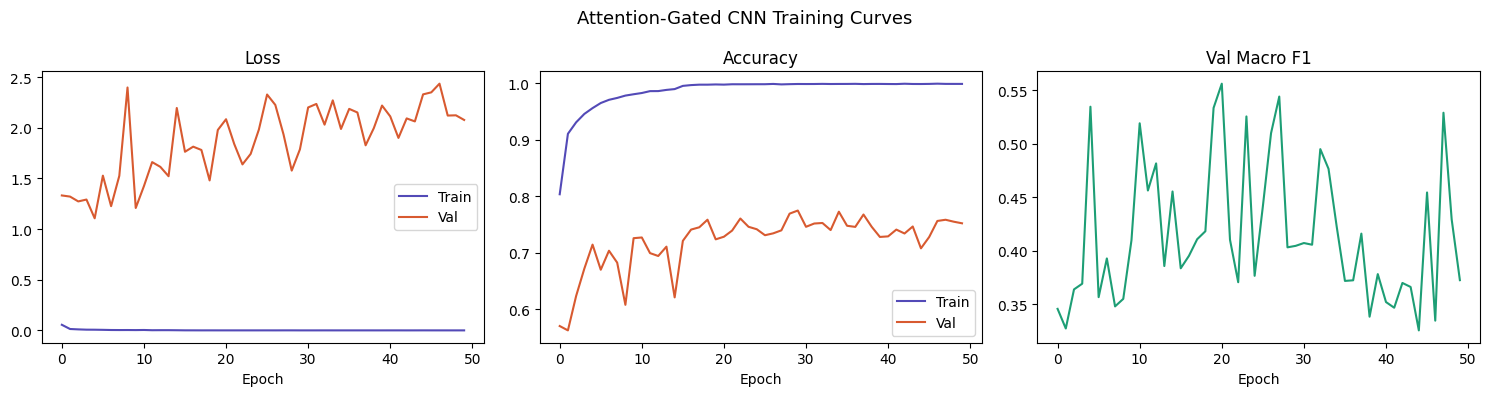

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history['train_loss'], label='Train', color='#534AB7')
axes[0].plot(history['val_loss'],   label='Val',   color='#D85A30')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].plot(history['train_acc'], label='Train', color='#534AB7')
axes[1].plot(history['val_acc'],   label='Val',   color='#D85A30')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].set_xlabel('Epoch')

axes[2].plot(history['val_f1'], color='#1D9E75')
axes[2].set_title('Val Macro F1'); axes[2].set_xlabel('Epoch')

plt.suptitle('Attention-Gated CNN Training Curves', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()

In [56]:
#Final Evaluation of Test set

Test Accuracy: 0.7968
Test Macro F1: 0.4122

                  precision    recall  f1-score   support

    MildDemented       0.18      0.23      0.20       427
ModerateDemented       0.00      0.00      0.00       244
     NonDemented       0.91      0.86      0.88     11346
VeryMildDemented       0.49      0.66      0.56      2135

        accuracy                           0.80     14152
       macro avg       0.39      0.44      0.41     14152
    weighted avg       0.81      0.80      0.80     14152



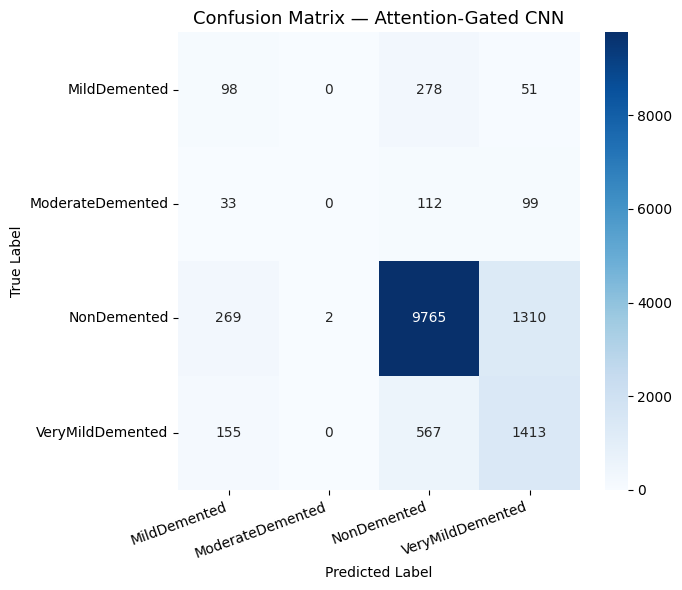


Results saved!


In [57]:
# Load best model
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pt'))
model.load_state_dict(checkpoint['model_state_dict'])

_, test_acc, test_f1, preds, labels = evaluate(model, test_loader, criterion, device)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1: {test_f1:.4f}")
print()
print(classification_report(labels, preds, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix — Attention-Gated CNN', fontsize=13)
ax.set_ylabel('True Label'); ax.set_xlabel('Predicted Label')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()

# Save results JSON for group comparison
results = {
    'model': 'Attention-Gated CNN (ResNet-18 backbone)',
    'test_accuracy': float(test_acc),
    'test_macro_f1': float(test_f1),
    'per_class_f1': {CLASS_NAMES[i]: float(f1_score(labels, preds, average=None)[i])
                     for i in range(N_CLASSES)},
    'hyperparams': {'lr': LR, 'batch_size': BATCH_SIZE, 'epochs': EPOCHS,
                    'unfreeze_epoch': UNFREEZE_EPOCH}
}
with open(os.path.join(SAVE_DIR, 'attention_cnn_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print("\nResults saved!")

In [58]:
#Grad-CAM visualization

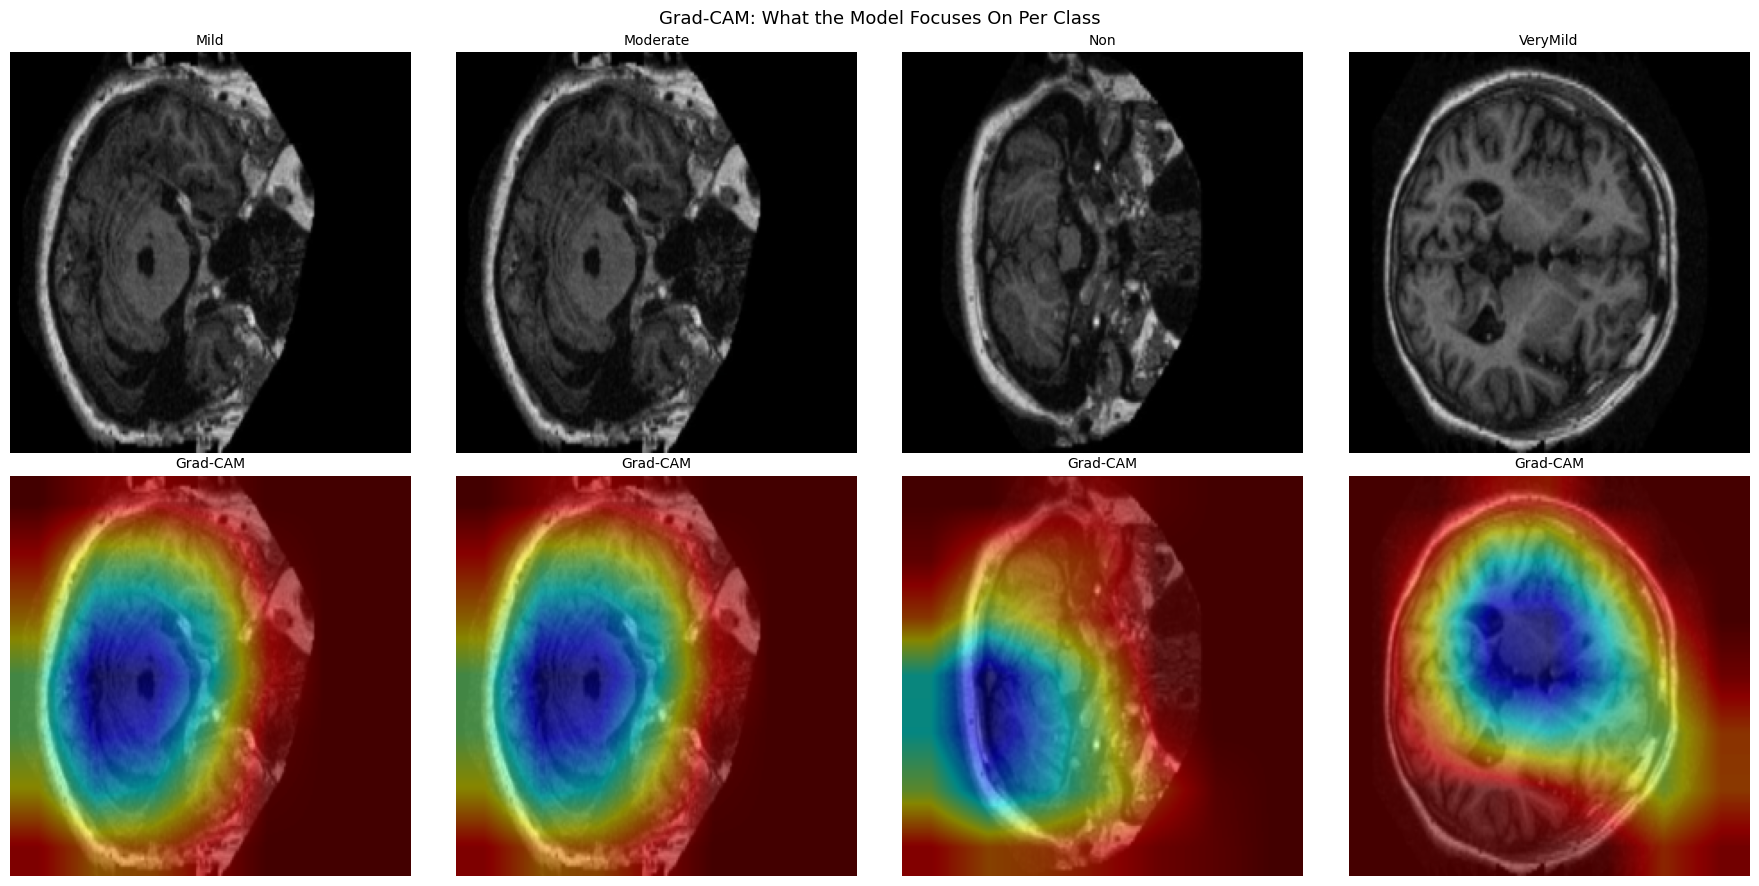

In [59]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Target the last conv layer of ResNet-18 backbone
target_layers = [model.enc5[-1].conv2]

cam = GradCAM(model=model, target_layers=target_layers)

# Visualize for one sample from each class
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

for col, cls_idx in enumerate(range(N_CLASSES)):
    # Find a correctly classified sample of this class
    for X, y in val_loader:
        mask = y == cls_idx
        if mask.sum() > 0:
            sample_x = X[mask][0:1].to(device)
            sample_y = y[mask][0].item()
            break

    # Original image
    img_np = inv_normalize(sample_x[0]).permute(1,2,0).cpu().numpy().clip(0,1)
    axes[0][col].imshow(img_np)
    axes[0][col].set_title(CLASS_NAMES[cls_idx].replace('Demented',''), fontsize=10)
    axes[0][col].axis('off')

    # Grad-CAM heatmap
    grayscale_cam = cam(input_tensor=sample_x)
    visualization = show_cam_on_image(img_np.astype(np.float32), grayscale_cam[0])
    axes[1][col].imshow(visualization)
    axes[1][col].set_title('Grad-CAM', fontsize=10)
    axes[1][col].axis('off')

axes[0][0].set_ylabel('Original MRI', fontsize=11)
axes[1][0].set_ylabel('Grad-CAM', fontsize=11)
plt.suptitle('Grad-CAM: What the Model Focuses On Per Class', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'gradcam_visualization.png'), dpi=150)
plt.show()

In [60]:
# Attention Map Vizualization

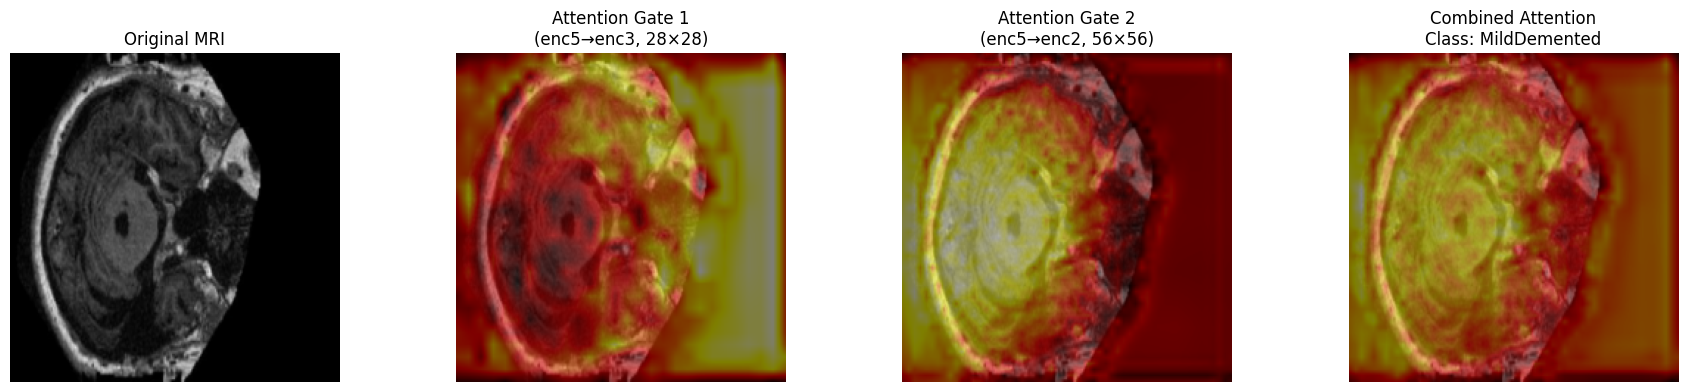

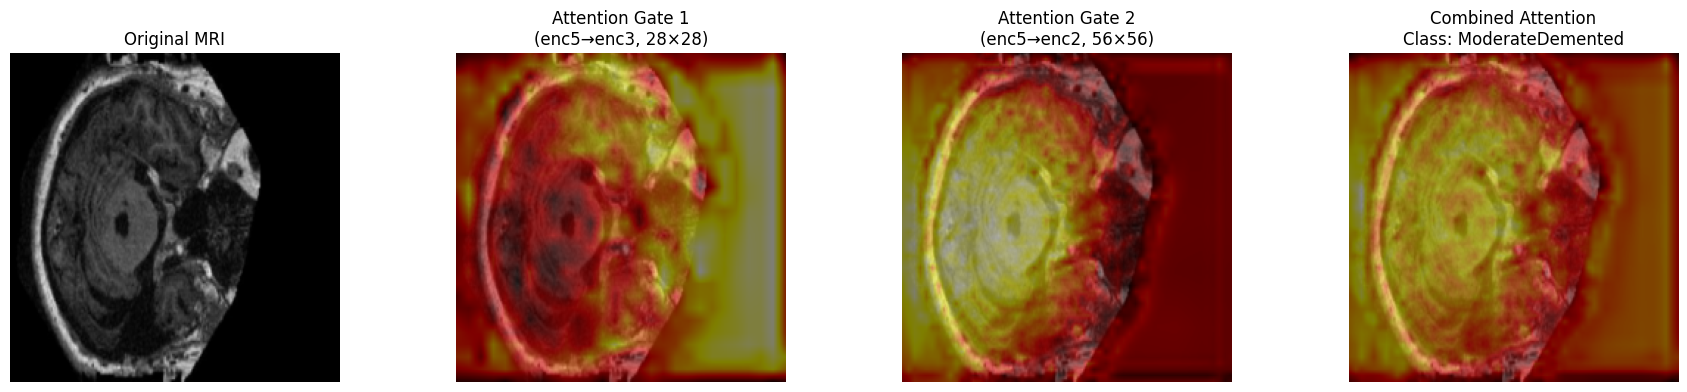

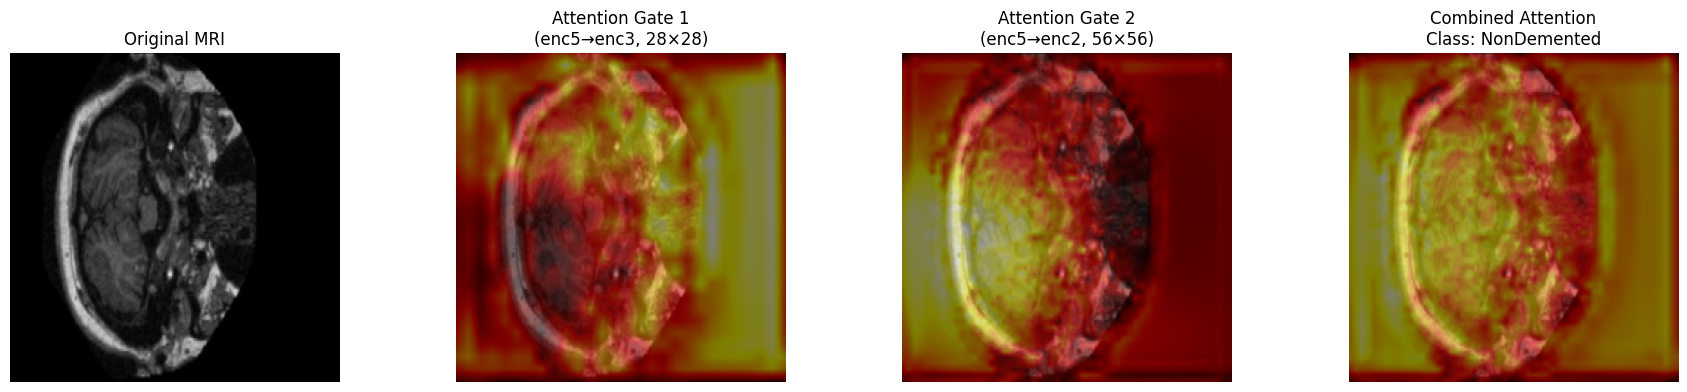

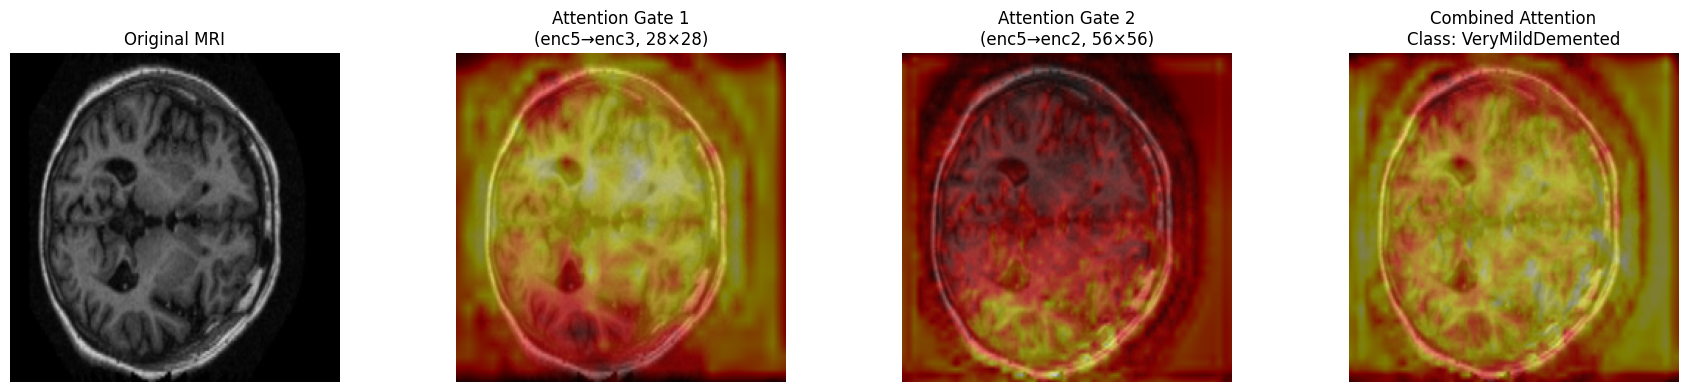

In [62]:
# not just Grad-CAM. Compare the two to see if they agree.

def visualize_attention_map(model, image_tensor, class_name, save_path=None):
    model.eval()
    with torch.no_grad():
        _, attn_dict = model(image_tensor.to(device), return_attention=True)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    inv_norm = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_np = inv_norm(image_tensor[0]).permute(1,2,0).numpy().clip(0,1)

    # Original
    axes[0].imshow(img_np); axes[0].set_title('Original MRI'); axes[0].axis('off')

    # Attention gate 1 (28x28 resolution — enc3 level)
    attn1 = attn_dict['attn1'][0, 0].cpu().numpy()
    attn1_up = F.interpolate(attn_dict['attn1'], size=(224,224),
                              mode='bilinear', align_corners=True)[0,0].cpu().numpy()
    axes[1].imshow(img_np)
    axes[1].imshow(attn1_up, cmap='hot', alpha=0.5)
    axes[1].set_title('Attention Gate 1\n(enc5→enc3, 28×28)'); axes[1].axis('off')

    # Attention gate 2 (56x56 resolution — enc2 level)
    attn2_up = F.interpolate(attn_dict['attn2'], size=(224,224),
                              mode='bilinear', align_corners=True)[0,0].cpu().numpy()
    axes[2].imshow(img_np)
    axes[2].imshow(attn2_up, cmap='hot', alpha=0.5)
    axes[2].set_title('Attention Gate 2\n(enc5→enc2, 56×56)'); axes[2].axis('off')

    # Combined attention
    combined = (attn1_up + attn2_up) / 2
    axes[3].imshow(img_np)
    axes[3].imshow(combined, cmap='hot', alpha=0.5)
    axes[3].set_title(f'Combined Attention\nClass: {class_name}'); axes[3].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Run for a sample from each class
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    for X, y in val_loader:
        mask = y == cls_idx
        if mask.sum() > 0:
            sample = X[mask][0:1]
            break
    visualize_attention_map(
        model, sample, cls_name,
        save_path=os.path.join(SAVE_DIR, f'attention_map_{cls_name}.png')
    )